# Vasicek Interest Rate Model

This notebook demonstrates the Vasicek single-factor mean-reverting interest rate model implementation.

## Contents

1. **Introduction to the Vasicek Model** - Theory and SDE formulation
2. **Loading Data** - Load historical short rate data
3. **Model Calibration** - Estimate parameters using MLE
4. **Parameter Interpretation** - Understanding κ, θ, and σ
5. **Monte Carlo Simulation** - Generate future rate paths
6. **Visualization** - Simulation paths and terminal distribution
7. **Analytical Formulas** - Expected rate and variance

## Prerequisites

- Completed Notebook 01: Data Exploration
- Sample treasury rates data loaded

## 1. Introduction to the Vasicek Model

The Vasicek model (1977) describes the evolution of short-term interest rates as a mean-reverting stochastic process:

$$dr_t = \kappa(\theta - r_t)dt + \sigma dW_t$$

Where:
- $r_t$ is the short rate at time $t$
- $\kappa$ (kappa) is the mean reversion speed
- $\theta$ (theta) is the long-term mean rate
- $\sigma$ (sigma) is the volatility
- $W_t$ is a Wiener process (Brownian motion)

### Key Properties

1. **Mean Reversion**: Rates tend to revert to the long-term mean $\theta$
2. **Negative Rates**: The model allows negative interest rates
3. **Closed-Form Solutions**: Analytical formulas exist for expected rate and variance

In [1]:
# Standard library imports
import sys
from pathlib import Path

# Add src to path for imports
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Third-party imports
import matplotlib.pyplot as plt
import numpy as np

# Project imports
from src.data.loader import load_interest_rate_data
from src.models.vasicek import VasicekModel
from src.visualization.simulation_plots import (
    plot_simulation_paths,
    plot_terminal_distribution,
)

# Configure plotting
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Imports complete.")

Imports complete.


## 2. Loading Data

We'll load the sample treasury rates and extract the short-term rate (3-month) for Vasicek calibration.

In [2]:
# Load the sample treasury rates
data_path = project_root / "data" / "sample_treasury_rates.csv"
dataset = load_interest_rate_data(data_path, date_column="date")

print(f"Loaded {dataset.n_observations} observations")
print(f"Date range: {dataset.date_range[0]} to {dataset.date_range[1]}")
print(f"Maturities: {dataset.maturities}")

# Extract short rate (3-month rate)
short_rates = dataset.rates[:, 0]  # First column = shortest maturity
print(f"\nShort rate statistics:")
print(f"  Mean: {np.mean(short_rates)*100:.4f}%")
print(f"  Std:  {np.std(short_rates)*100:.4f}%")
print(f"  Min:  {np.min(short_rates)*100:.4f}%")
print(f"  Max:  {np.max(short_rates)*100:.4f}%")

2026-01-20 21:27:38 | INFO     | hjm_vasicek.data.loader | Loading interest rate data from /home/haydar/personal/act/data/sample_treasury_rates.csv
2026-01-20 21:27:38 | INFO     | hjm_vasicek.data.loader | Loaded 252 observations with 7 maturities from sample_treasury_rates
Loaded 252 observations
Date range: 2024-01-02 to 2024-12-18
Maturities: [ 0.25  0.5   1.    2.    5.   10.   30.  ]

Short rate statistics:
  Mean: 5.4096%
  Std:  0.1884%
  Min:  4.9395%
  Max:  5.7962%


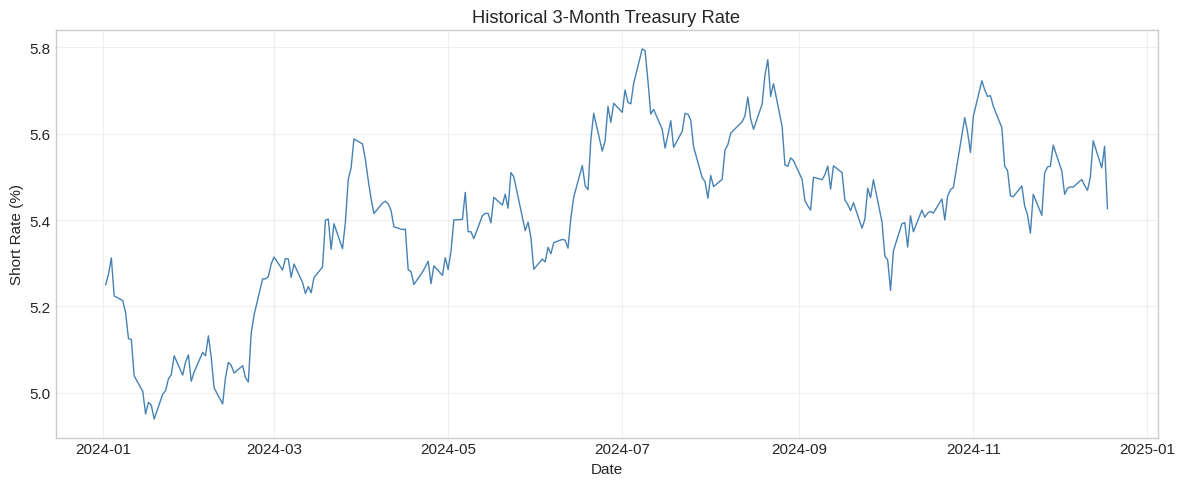

In [3]:
# Plot the historical short rate series
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dataset.observation_dates, short_rates * 100, color='steelblue', linewidth=1)
ax.set_xlabel('Date')
ax.set_ylabel('Short Rate (%)')
ax.set_title('Historical 3-Month Treasury Rate')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Model Calibration

We calibrate the Vasicek model using Maximum Likelihood Estimation (MLE).

The discretized Vasicek process follows:
$$r_{t+\Delta t} = r_t + \kappa(\theta - r_t)\Delta t + \sigma\sqrt{\Delta t}\epsilon$$

where $\epsilon \sim N(0,1)$. This is an AR(1) process, making MLE straightforward.

In [4]:
# Create and calibrate the Vasicek model
model = VasicekModel()

# Calibrate using MLE with daily time step
dt = 1 / 252  # Daily data (252 trading days per year)
model.calibrate(short_rates, dt=dt, method="mle")

print("=" * 60)
print("VASICEK MODEL CALIBRATION RESULTS")
print("=" * 60)
print(f"\nConvergence: {model.convergence_status}")
print(f"Calibration date: {model.calibration_date}")
if model.log_likelihood:
    print(f"Log-likelihood: {model.log_likelihood:.2f}")

print("\nEstimated Parameters:")
params = model.get_parameters()
for name, value in params.items():
    if name == 'theta':
        print(f"  {name}: {value:.6f} ({value*100:.4f}%)")
    elif name == 'sigma':
        print(f"  {name}: {value:.6f} ({value*100:.4f}%/√year)")
    else:
        print(f"  {name}: {value:.4f}/year")

2026-01-20 21:27:39 | INFO     | hjm_vasicek.models.vasicek | Calibrating Vasicek to 252 rate observations
2026-01-20 21:27:39 | INFO     | hjm_vasicek.models.vasicek | MLE calibration converged: kappa=8.3648, theta=0.054307, sigma=0.007473, LL=1573.03
VASICEK MODEL CALIBRATION RESULTS

Convergence: converged
Calibration date: 2026-01-20 21:27:39.170437
Log-likelihood: 1573.03

Estimated Parameters:
  kappa: 8.3648/year
  theta: 0.054307 (5.4307%)
  sigma: 0.007473 (0.7473%/√year)


## 4. Parameter Interpretation

The model provides plain-language interpretations of each parameter.

In [5]:
# Get plain-language parameter interpretations
interpretations = model.get_parameter_interpretations()

print("=" * 70)
print("PARAMETER INTERPRETATIONS")
print("=" * 70)

for param, explanation in interpretations.items():
    print(f"\n{param.upper()}:")
    print(f"  {explanation}")

PARAMETER INTERPRETATIONS

KAPPA:
  Mean reversion speed: κ = 8.3648/year. The interest rate reverts halfway to its long-term mean in approximately 0.08 years.

THETA:
  Long-term mean rate: θ = 5.4307%. This is the equilibrium level to which interest rates tend to revert over time.

SIGMA:
  Volatility: σ = 0.7473%/√year. This produces a long-run standard deviation of approximately 0.1827% around the mean.


In [6]:
# Visualize the mean reversion effect
half_life = np.log(2) / model.kappa

print(f"\nMean Reversion Analysis:")
print(f"  Half-life: {half_life:.2f} years ({half_life*252:.0f} trading days)")
print(f"  After 1 year: {np.exp(-model.kappa)*100:.1f}% of deviation remains")
print(f"  After 5 years: {np.exp(-5*model.kappa)*100:.1f}% of deviation remains")


Mean Reversion Analysis:
  Half-life: 0.08 years (21 trading days)
  After 1 year: 0.0% of deviation remains
  After 5 years: 0.0% of deviation remains


## 5. Monte Carlo Simulation

We simulate future interest rate paths using the Euler-Maruyama discretization scheme:

$$r_{t+\Delta t} = r_t + \kappa(\theta - r_t)\Delta t + \sigma\sqrt{\Delta t}\epsilon$$

In [7]:
# Simulation parameters
n_paths = 1000  # Number of simulation paths
time_horizon = 1.0  # 1 year
time_step = 1 / 252  # Daily steps
initial_rate = short_rates[-1]  # Start from last observed rate

print(f"Simulation Configuration:")
print(f"  Number of paths: {n_paths:,}")
print(f"  Time horizon: {time_horizon} years")
print(f"  Time step: {time_step:.6f} years (daily)")
print(f"  Initial rate: {initial_rate*100:.4f}%")
print(f"  Random seed: 42 (for reproducibility)")

# Run simulation
result = model.simulate(
    n_paths=n_paths,
    time_horizon=time_horizon,
    time_step=time_step,
    initial_rate=initial_rate,
    random_seed=42,
)

print(f"\nSimulation complete!")
print(f"  Generated {result.path_count:,} paths")
print(f"  Each path has {result.n_time_points} time points")

Simulation Configuration:
  Number of paths: 1,000
  Time horizon: 1.0 years
  Time step: 0.003968 years (daily)
  Initial rate: 5.4259%
  Random seed: 42 (for reproducibility)
2026-01-20 21:27:39 | INFO     | hjm_vasicek.models.vasicek | Simulating 1000 paths over 1.00 years with dt=0.003968
2026-01-20 21:27:39 | INFO     | hjm_vasicek.models.vasicek | Simulation complete: 1000 paths, terminal mean=0.054322, terminal std=0.001808

Simulation complete!
  Generated 1,000 paths
  Each path has 253 time points


In [8]:
# Summary statistics of terminal rates
terminal_rates = result.terminal_distribution()

print("\nTerminal Rate Distribution (at T=1 year):")
print(f"  Mean:   {result.terminal_mean()*100:.4f}%")
print(f"  Std:    {result.terminal_std()*100:.4f}%")
print(f"  Min:    {np.min(terminal_rates)*100:.4f}%")
print(f"  Max:    {np.max(terminal_rates)*100:.4f}%")

percentiles = result.terminal_percentiles([5, 25, 50, 75, 95])
print(f"\nPercentiles:")
for p, val in percentiles.items():
    print(f"  {p:3.0f}th: {val*100:.4f}%")


Terminal Rate Distribution (at T=1 year):
  Mean:   5.4322%
  Std:    0.1808%
  Min:    4.8557%
  Max:    5.9663%

Percentiles:
    5th: 5.1392%
   25th: 5.3094%
   50th: 5.4364%
   75th: 5.5573%
   95th: 5.7236%


## 6. Visualization

Let's visualize the simulation results with paths, mean, and percentile bands.

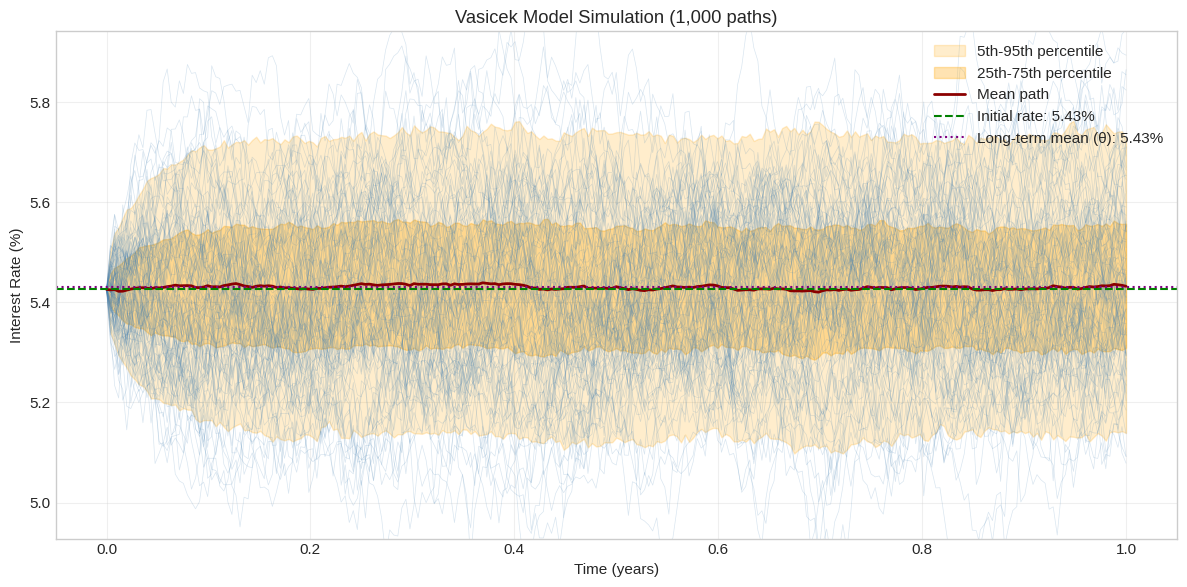

In [9]:
# Plot simulation paths with percentile bands
fig = plot_simulation_paths(
    result,
    n_paths=100,  # Show 100 individual paths
    show_mean=True,
    show_percentiles=True,
    alpha=0.2,
)

# Add initial rate and theta reference lines
ax = fig.axes[0]
ax.axhline(y=initial_rate*100, color='green', linestyle='--', linewidth=1.5, 
           label=f'Initial rate: {initial_rate*100:.2f}%')
ax.axhline(y=model.theta*100, color='purple', linestyle=':', linewidth=1.5,
           label=f'Long-term mean (θ): {model.theta*100:.2f}%')
ax.legend(loc='upper right')

plt.show()

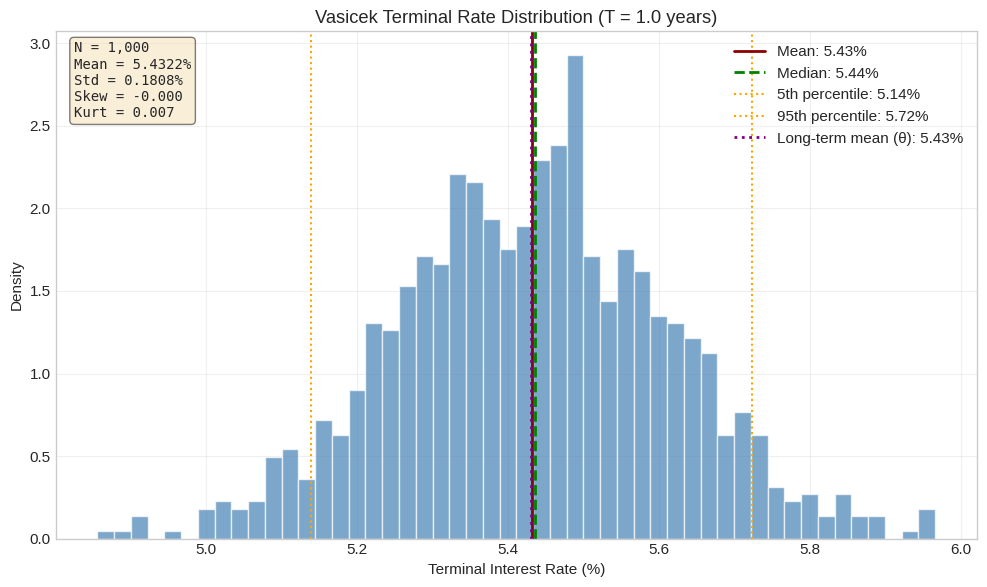

In [10]:
# Plot terminal rate distribution
fig = plot_terminal_distribution(
    result,
    bins=50,
    show_stats=True,
    show_density=True,
)

# Add theta reference line
ax = fig.axes[0]
ax.axvline(x=model.theta*100, color='purple', linestyle=':', linewidth=2,
           label=f'Long-term mean (θ): {model.theta*100:.2f}%')
ax.legend(loc='upper right')

plt.show()

## 7. Analytical Formulas

The Vasicek model has closed-form solutions for the expected rate and variance.

### Expected Rate
$$E[r_t] = r_0 e^{-\kappa t} + \theta (1 - e^{-\kappa t})$$

### Variance
$$Var[r_t] = \frac{\sigma^2}{2\kappa} (1 - e^{-2\kappa t})$$

In [11]:
# Compare analytical vs simulated values
t_values = [0.25, 0.5, 1.0, 2.0, 5.0]

print("Analytical vs Simulated Comparison:")
print("=" * 70)
print(f"{'Time':>6} | {'E[r] Analytical':>15} | {'Var[r] Analytical':>18} | {'Std[r]':>12}")
print("-" * 70)

for t in t_values:
    expected = model.expected_rate(t=t, r0=initial_rate)
    variance = model.rate_variance(t=t)
    std = np.sqrt(variance)
    print(f"{t:>6.2f} | {expected*100:>14.4f}% | {variance*10000:>15.6f} bp² | {std*100:>10.4f}%")

print("-" * 70)
print(f"\nLong-run equilibrium (t→∞):")
print(f"  Expected rate: {model.theta*100:.4f}%")
long_run_var = model.sigma**2 / (2 * model.kappa)
long_run_std = np.sqrt(long_run_var)
print(f"  Variance: {long_run_var*10000:.6f} bp²")
print(f"  Standard deviation: {long_run_std*100:.4f}%")

Analytical vs Simulated Comparison:
  Time | E[r] Analytical |  Var[r] Analytical |       Std[r]
----------------------------------------------------------------------
  0.25 |         5.4301% |        0.032874 bp² |     0.1813%
  0.50 |         5.4306% |        0.033376 bp² |     0.1827%
  1.00 |         5.4307% |        0.033384 bp² |     0.1827%
  2.00 |         5.4307% |        0.033384 bp² |     0.1827%
  5.00 |         5.4307% |        0.033384 bp² |     0.1827%
----------------------------------------------------------------------

Long-run equilibrium (t→∞):
  Expected rate: 5.4307%
  Variance: 0.033384 bp²
  Standard deviation: 0.1827%


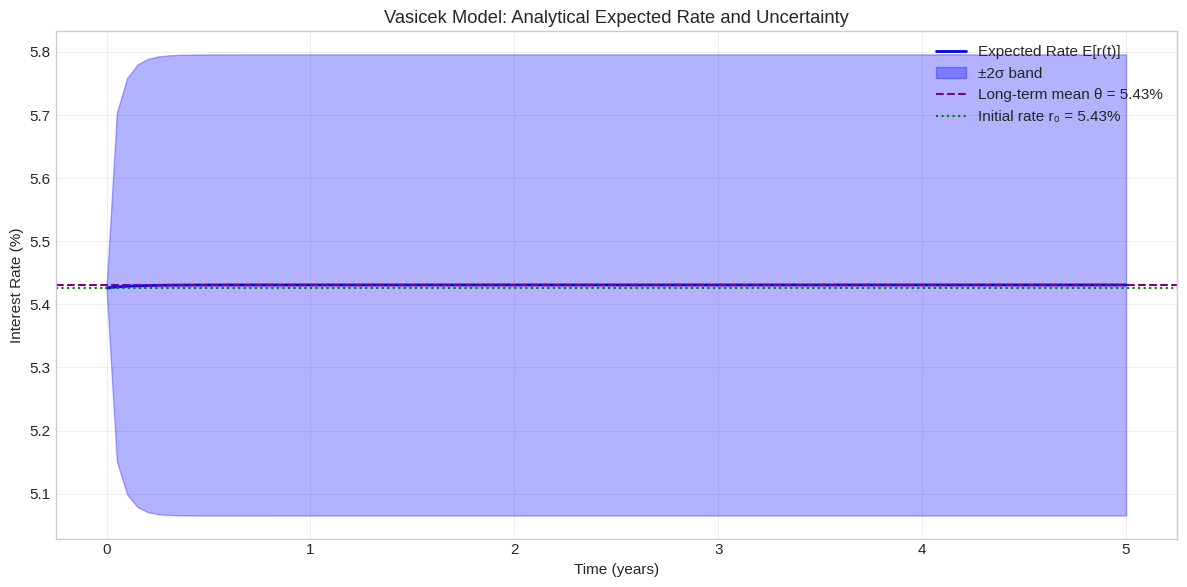

In [12]:
# Plot expected rate evolution over time
times = np.linspace(0, 5, 100)
expected_rates = [model.expected_rate(t=t, r0=initial_rate) for t in times]
stds = [np.sqrt(model.rate_variance(t=t)) for t in times]

fig, ax = plt.subplots(figsize=(12, 6))

# Expected rate
ax.plot(times, np.array(expected_rates)*100, 'b-', linewidth=2, label='Expected Rate E[r(t)]')

# Confidence bands (±2σ)
upper = (np.array(expected_rates) + 2*np.array(stds)) * 100
lower = (np.array(expected_rates) - 2*np.array(stds)) * 100
ax.fill_between(times, lower, upper, alpha=0.3, color='blue', label='±2σ band')

# Reference lines
ax.axhline(y=model.theta*100, color='purple', linestyle='--', linewidth=1.5,
           label=f'Long-term mean θ = {model.theta*100:.2f}%')
ax.axhline(y=initial_rate*100, color='green', linestyle=':', linewidth=1.5,
           label=f'Initial rate r₀ = {initial_rate*100:.2f}%')

ax.set_xlabel('Time (years)')
ax.set_ylabel('Interest Rate (%)')
ax.set_title('Vasicek Model: Analytical Expected Rate and Uncertainty')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Summary

In this notebook, we:

1. **Loaded** historical short rate data from sample treasury rates
2. **Calibrated** the Vasicek model using Maximum Likelihood Estimation
3. **Interpreted** the parameters (κ, θ, σ) in plain language
4. **Simulated** 1,000 rate paths using Monte Carlo simulation
5. **Visualized** the simulation paths and terminal distribution
6. **Verified** the simulation against analytical formulas

### Key Findings

- The calibrated parameters suggest mean reversion toward the long-term mean
- The half-life indicates how quickly rates revert after shocks
- Simulated terminal rates match the analytical distribution well

### Next Steps

- **Notebook 03**: PCA Analysis of yield curves
- **Notebook 04**: HJM model with PCA factors
- **Notebook 05**: Model comparison and backtesting